In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 10
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

# Enable memory growth before TensorFlow initializes GPU contexts.
physical_gpus = tf.config.list_physical_devices("GPU")
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("Could not set memory growth:", exc)

# Use both GPUs when available, as in our previous SAMSum experiment.
strategy = (
    tf.distribute.MirroredStrategy()
    if len(physical_gpus) > 1
    else tf.distribute.get_strategy()
)

print("TensorFlow:", tf.__version__)
print("Physical GPUs:", physical_gpus)
print("Replicas:", strategy.num_replicas_in_sync)
print("Mixed precision: OFF (keeps this experiment close to the assignment)")

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
TensorFlow: 2.21.0
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Replicas: 2
Mixed precision: OFF (keeps this experiment close to the assignment)


In [2]:
def find_samsum_directory(root="/kaggle/input"):
    root_path = Path(root)
    if not root_path.exists():
        raise FileNotFoundError(
            f"{root} does not exist. This notebook expects the SAMSum Kaggle dataset."
        )

    candidates = []
    for train_file in root_path.rglob("train.json"):
        parent = train_file.parent
        if all((parent / name).exists() for name in ("val.json", "test.json")):
            candidates.append(parent)

    if not candidates:
        raise FileNotFoundError(
            "Could not find a directory containing train.json, val.json, and test.json. "
            "Check that the SAMSum dataset is attached to this Kaggle notebook."
        )
    return candidates[0]

DATA_DIR = find_samsum_directory()
print("Dataset directory:", DATA_DIR)


def read_json_records(path):
    with open(path, "r", encoding="utf-8") as file:
        data = json.load(file)
    if not isinstance(data, list):
        raise ValueError(f"Expected a JSON list in {path}, got {type(data).__name__}")
    return data

raw_train = read_json_records(DATA_DIR / "train.json")
raw_val = read_json_records(DATA_DIR / "val.json")
raw_test = read_json_records(DATA_DIR / "test.json")

print("Raw counts:", len(raw_train), len(raw_val), len(raw_test))

Dataset directory: /kaggle/input/datasets/cykadyy/samsummarization
Raw counts: 14732 818 819


In [3]:
def normalize_text(text):
    text = str(text or "")
    text = text.replace("\r\n", " ").replace("\n", " ").replace("\r", " ")
    text = re.sub(r"<file_[^>]+>", " ", text, flags=re.IGNORECASE)
    return " ".join(text.split()).strip()


def clean_exact_pairs(records):
    cleaned = []
    seen_pairs = set()
    for record in records:
        dialogue = normalize_text(record.get("dialogue", ""))
        summary = normalize_text(record.get("summary", ""))
        if not dialogue or not summary:
            continue
        pair = (dialogue.lower(), summary.lower())
        if pair in seen_pairs:
            continue
        seen_pairs.add(pair)
        cleaned.append({
            "id": str(record.get("id", "")),
            "dialogue": dialogue,
            "summary": summary,
        })
    return cleaned

# Remove cross-split dialogue overlaps with strict priority: test > validation > train.
test_records = clean_exact_pairs(raw_test)
test_dialogues = {r["dialogue"].lower() for r in test_records}

val_candidates = clean_exact_pairs(raw_val)
val_records = [r for r in val_candidates if r["dialogue"].lower() not in test_dialogues]
val_dialogues = {r["dialogue"].lower() for r in val_records}

train_candidates = clean_exact_pairs(raw_train)
blocked_dialogues = test_dialogues | val_dialogues
train_records = [r for r in train_candidates if r["dialogue"].lower() not in blocked_dialogues]
print("\nCleaned split sizes")
print("Train:", len(train_records))
print("Validation:", len(val_records))
print("Test:", len(test_records))

assert not ({r["dialogue"].lower() for r in train_records} & val_dialogues)
assert not ({r["dialogue"].lower() for r in train_records} & test_dialogues)
assert not (val_dialogues & test_dialogues)
print("Cross-split dialogue overlap: 0")

print("\nExample dialogue:\n", train_records[0]["dialogue"])
print("\nExample reference summary:\n", train_records[0]["summary"])


Cleaned split sizes
Train: 14637
Validation: 814
Test: 819
Cross-split dialogue overlap: 0

Example dialogue:
 Amanda: I baked cookies. Do you want some? Jerry: Sure! Amanda: I'll bring you tomorrow :-)

Example reference summary:
 Amanda baked cookies and will bring Jerry some tomorrow.


In [4]:
SOS_TOKEN = "[SOS]"
EOS_TOKEN = "[EOS]"
UNK_TOKEN = "[UNK]"
PAD_ID = 0

# Mirror the assignment: lowercase text, preserve square brackets, and wrap with SOS/EOS.
def prepare_text(text):
    text = normalize_text(text).lower()
    return f"{SOS_TOKEN} {text} {EOS_TOKEN}"

train_documents = [prepare_text(r["dialogue"]) for r in train_records]
train_summaries = [prepare_text(r["summary"]) for r in train_records]
val_documents = [prepare_text(r["dialogue"]) for r in val_records]
val_summaries = [prepare_text(r["summary"]) for r in val_records]
test_documents = [prepare_text(r["dialogue"]) for r in test_records]
test_summaries = [prepare_text(r["summary"]) for r in test_records]

filters = '"#$%&()*+,-./:;<=>?@\\^_`{|}~\t\n'
filters = '!' + filters

tokenizer = tf.keras.preprocessing.text.Tokenizer(
    filters=filters,
    oov_token=UNK_TOKEN,
    lower=False,
)
tokenizer.fit_on_texts(train_documents + train_summaries)

SOS_ID = tokenizer.word_index.get(SOS_TOKEN)
EOS_ID = tokenizer.word_index.get(EOS_TOKEN)
UNK_ID = tokenizer.word_index.get(UNK_TOKEN)
if SOS_ID is None or EOS_ID is None or UNK_ID is None:
    raise RuntimeError("Tokenizer did not preserve [SOS], [EOS], or [UNK]. Check the filters string.")

vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocab_size)
print("PAD / UNK / SOS / EOS:", PAD_ID, UNK_ID, SOS_ID, EOS_ID)
print("Tokenizer sample:", tokenizer.texts_to_sequences([train_documents[0]])[0][:30])

Vocabulary size: 34145
PAD / UNK / SOS / EOS: 0 1 7 8
Tokenizer sample: [7, 446, 2, 3484, 1602, 30, 5, 80, 50, 612, 66, 446, 63, 218, 5, 97, 8]


In [5]:
encoder_maxlen = 150
decoder_maxlen = 50
GLOBAL_BATCH_SIZE = 64
EPOCHS = 20


def encode_and_pad(texts, maxlen):
    sequences = tokenizer.texts_to_sequences(texts)
    padded = tf.keras.preprocessing.sequence.pad_sequences(
        sequences,
        maxlen=maxlen,
        padding="post",
        truncating="post",
    )
    return np.asarray(padded, dtype=np.int32), sequences

train_inputs, train_input_sequences = encode_and_pad(train_documents, encoder_maxlen)
train_targets, train_target_sequences = encode_and_pad(train_summaries, decoder_maxlen)
val_inputs, val_input_sequences = encode_and_pad(val_documents, encoder_maxlen)
val_targets, val_target_sequences = encode_and_pad(val_summaries, decoder_maxlen)
test_inputs, test_input_sequences = encode_and_pad(test_documents, encoder_maxlen)
test_targets, test_target_sequences = encode_and_pad(test_summaries, decoder_maxlen)

print("Train inputs:", train_inputs.shape)
print("Train targets:", train_targets.shape)
print("Validation inputs:", val_inputs.shape)
print("Validation targets:", val_targets.shape)
print("Test inputs:", test_inputs.shape)
print("Test targets:", test_targets.shape)

def truncation_rate(sequences, maxlen):
    return 100.0 * sum(len(seq) > maxlen for seq in sequences) / max(1, len(sequences))

print(f"Source truncation: train={truncation_rate(train_input_sequences, encoder_maxlen):.2f}% | "
      f"val={truncation_rate(val_input_sequences, encoder_maxlen):.2f}% | "
      f"test={truncation_rate(test_input_sequences, encoder_maxlen):.2f}%")
print(f"Target truncation: train={truncation_rate(train_target_sequences, decoder_maxlen):.2f}% | "
      f"val={truncation_rate(val_target_sequences, decoder_maxlen):.2f}% | "
      f"test={truncation_rate(test_target_sequences, decoder_maxlen):.2f}%")

train_dataset = (
    tf.data.Dataset.from_tensor_slices((train_inputs, train_targets))
    .shuffle(min(10000, len(train_inputs)), seed=SEED, reshuffle_each_iteration=True)
    .batch(GLOBAL_BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)
val_dataset = (
    tf.data.Dataset.from_tensor_slices((val_inputs, val_targets))
    .batch(GLOBAL_BATCH_SIZE, drop_remainder=False)
    .prefetch(tf.data.AUTOTUNE)
)

train_dist_dataset = strategy.experimental_distribute_dataset(train_dataset)
val_dist_dataset = strategy.experimental_distribute_dataset(val_dataset)
print("Train batches per epoch:", len(train_inputs) // GLOBAL_BATCH_SIZE)
print("Validation batches:", int(np.ceil(len(val_inputs) / GLOBAL_BATCH_SIZE)))

Train inputs: (14637, 150)
Train targets: (14637, 50)
Validation inputs: (814, 150)
Validation targets: (814, 50)
Test inputs: (819, 150)
Test targets: (819, 50)
Source truncation: train=17.89% | val=16.95% | test=18.68%
Target truncation: train=2.53% | val=2.58% | test=1.47%
Train batches per epoch: 228
Validation batches: 13


In [6]:
def positional_encoding(positions, d_model):
    position = np.arange(positions)[:, np.newaxis]
    k = np.arange(d_model)[np.newaxis, :]
    i = k // 2
    angle_rates = 1 / np.power(10000, (2 * i) / np.float32(d_model))
    angle_rads = position * angle_rates
    angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
    angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
    return tf.cast(angle_rads[np.newaxis, ...], dtype=tf.float32)


def create_padding_mask(token_ids):
    # True means the key/value position is valid and may be attended to.
    return tf.not_equal(token_ids[:, tf.newaxis, :], PAD_ID)


def create_look_ahead_mask(sequence_length):
    mask = tf.linalg.band_part(
        tf.ones((1, sequence_length, sequence_length), dtype=tf.int32), -1, 0
    )
    return tf.cast(mask, tf.bool)

# Quick shape check.
print("Padding mask:", create_padding_mask(tf.constant([[2, 3, 0, 0]])).shape)
print("Look-ahead mask:", create_look_ahead_mask(4).shape)

Padding mask: (1, 1, 4)
Look-ahead mask: (1, 4, 4)


In [7]:
def scaled_dot_product_attention(q, k, v, mask=None):
    matmul_qk = tf.matmul(q, k, transpose_b=True)
    dk = tf.cast(tf.shape(k)[-1], tf.float32)
    scaled_logits = matmul_qk / tf.math.sqrt(dk)
    if mask is not None:
        scaled_logits += tf.cast(tf.logical_not(mask), scaled_logits.dtype) * tf.cast(-1e9, scaled_logits.dtype)
    attention_weights = tf.nn.softmax(scaled_logits, axis=-1)
    output = tf.matmul(attention_weights, v)
    return output, attention_weights


def FullyConnected(embedding_dim, fully_connected_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Dense(fully_connected_dim, activation="relu"),
        tf.keras.layers.Dense(embedding_dim),
    ])

In [8]:
class EncoderLayer(tf.keras.layers.Layer):
    def __init__(self, embedding_dim, num_heads, fully_connected_dim,
                 dropout_rate=0.1, layernorm_eps=1e-6):
        super().__init__()
        self.mha = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embedding_dim,
            dropout=dropout_rate,
        )
        self.ffn = FullyConnected(embedding_dim, fully_connected_dim)
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=layernorm_eps)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=layernorm_eps)
        self.dropout_ffn = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, training=False, mask=None):
        attn_output = self.mha(
            query=x, key=x, value=x, attention_mask=mask, training=training
        )
        x1 = self.layernorm1(x + attn_output)
        ffn_output = self.ffn(x1)
        ffn_output = self.dropout_ffn(ffn_output, training=training)
        return self.layernorm2(x1 + ffn_output)


class Encoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, embedding_dim, num_heads, fully_connected_dim,
                 input_vocab_size, maximum_position_encoding,
                 dropout_rate=0.1, layernorm_eps=1e-6):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.embedding = tf.keras.layers.Embedding(input_vocab_size, embedding_dim)
        self.pos_encoding = positional_encoding(maximum_position_encoding, embedding_dim)
        self.enc_layers = [
            EncoderLayer(embedding_dim, num_heads, fully_connected_dim,
                        dropout_rate, layernorm_eps)
            for _ in range(num_layers)
        ]
        self.dropout = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, training=False, mask=None):
        seq_len = tf.shape(x)[1]
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.embedding_dim, tf.float32))
        x += tf.cast(self.pos_encoding[:, :seq_len, :], x.dtype)
        x = self.dropout(x, training=training)
        for layer in self.enc_layers:
            x = layer(x, training=training, mask=mask)
        return x

In [9]:
class DecoderLayer(tf.keras.layers.Layer):
    def __init__(self, embedding_dim, num_heads, fully_connected_dim,
                 dropout_rate=0.1, layernorm_eps=1e-6):
        super().__init__()
        self.mha1 = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embedding_dim, dropout=dropout_rate
        )
        self.mha2 = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embedding_dim, dropout=dropout_rate
        )
        self.ffn = FullyConnected(embedding_dim, fully_connected_dim)
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=layernorm_eps)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=layernorm_eps)
        self.layernorm3 = tf.keras.layers.LayerNormalization(epsilon=layernorm_eps)
        self.dropout_ffn = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, enc_output, training=False,
             look_ahead_mask=None, padding_mask=None):
        attn1 = self.mha1(
            query=x, key=x, value=x,
            attention_mask=look_ahead_mask,
            training=training,
        )
        out1 = self.layernorm1(x + attn1)

        attn2 = self.mha2(
            query=out1, key=enc_output, value=enc_output,
            attention_mask=padding_mask,
            training=training,
        )
        out2 = self.layernorm2(out1 + attn2)

        ffn_output = self.ffn(out2)
        ffn_output = self.dropout_ffn(ffn_output, training=training)
        return self.layernorm3(out2 + ffn_output)


class Decoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, embedding_dim, num_heads, fully_connected_dim,
                 target_vocab_size, maximum_position_encoding,
                 dropout_rate=0.1, layernorm_eps=1e-6):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.embedding = tf.keras.layers.Embedding(target_vocab_size, embedding_dim)
        self.pos_encoding = positional_encoding(maximum_position_encoding, embedding_dim)
        self.dec_layers = [
            DecoderLayer(embedding_dim, num_heads, fully_connected_dim,
                        dropout_rate, layernorm_eps)
            for _ in range(num_layers)
        ]
        self.dropout = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, enc_output, training=False,
             look_ahead_mask=None, padding_mask=None):
        seq_len = tf.shape(x)[1]
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.embedding_dim, tf.float32))
        x += tf.cast(self.pos_encoding[:, :seq_len, :], x.dtype)
        x = self.dropout(x, training=training)
        for layer in self.dec_layers:
            x = layer(
                x, enc_output, training=training,
                look_ahead_mask=look_ahead_mask,
                padding_mask=padding_mask,
            )
        return x

In [10]:
class Transformer(tf.keras.Model):
    def __init__(self, num_layers, embedding_dim, num_heads, fully_connected_dim,
                 input_vocab_size, target_vocab_size,
                 max_positional_encoding_input, max_positional_encoding_target,
                 dropout_rate=0.1, layernorm_eps=1e-6):
        super().__init__()
        self.encoder = Encoder(
            num_layers, embedding_dim, num_heads, fully_connected_dim,
            input_vocab_size, max_positional_encoding_input,
            dropout_rate, layernorm_eps,
        )
        self.decoder = Decoder(
            num_layers, embedding_dim, num_heads, fully_connected_dim,
            target_vocab_size, max_positional_encoding_target,
            dropout_rate, layernorm_eps,
        )
        self.final_layer = tf.keras.layers.Dense(target_vocab_size, activation="softmax")

    def call(self, input_sentence, output_sentence, training=False,
             enc_padding_mask=None, look_ahead_mask=None, dec_padding_mask=None):
        enc_output = self.encoder(
            input_sentence, training=training, mask=enc_padding_mask
        )
        dec_output = self.decoder(
            output_sentence, enc_output, training=training,
            look_ahead_mask=look_ahead_mask,
            padding_mask=dec_padding_mask,
        )
        return self.final_layer(dec_output)


NUM_LAYERS = 4
EMBEDDING_DIM = 256
FULLY_CONNECTED_DIM = 1024
NUM_HEADS = 8
POSITIONAL_ENCODING_LENGTH = 256
DROPOUT_RATE = 0.1

with strategy.scope():
    transformer = Transformer(
        num_layers=NUM_LAYERS,
        embedding_dim=EMBEDDING_DIM,
        num_heads=NUM_HEADS,
        fully_connected_dim=FULLY_CONNECTED_DIM,
        input_vocab_size=vocab_size,
        target_vocab_size=vocab_size,
        max_positional_encoding_input=POSITIONAL_ENCODING_LENGTH,
        max_positional_encoding_target=POSITIONAL_ENCODING_LENGTH,
        dropout_rate=DROPOUT_RATE,
    )

    dummy_source = tf.zeros((1, encoder_maxlen), dtype=tf.int32)
    dummy_target = tf.zeros((1, decoder_maxlen - 1), dtype=tf.int32)
    transformer(
        dummy_source,
        dummy_target,
        training=False,
        enc_padding_mask=create_padding_mask(dummy_source),
        look_ahead_mask=create_look_ahead_mask(tf.shape(dummy_target)[1]),
        dec_padding_mask=create_padding_mask(dummy_source),
    )

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.9,
        beta_2=0.98,
        epsilon=1e-9,
    )

    optimizer.build(transformer.trainable_variables)
    print("Adam optimizer variables initialized:", len(optimizer.variables))

print("Trainable parameters:", f"{transformer.count_params():,}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer_1' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'encoder_layer_2' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/loca

Adam optimizer variables initialized: 346
Trainable parameters: 55,714,913


In [11]:
def token_loss_and_counts(real, predictions):
    per_token_loss = tf.keras.losses.sparse_categorical_crossentropy(
        real, predictions, from_logits=False
    )
    valid_mask = tf.cast(tf.not_equal(real, PAD_ID), per_token_loss.dtype)
    loss_sum = tf.reduce_sum(per_token_loss * valid_mask)
    token_count = tf.reduce_sum(valid_mask)
    predicted_ids = tf.argmax(predictions, axis=-1, output_type=tf.int32)
    correct_count = tf.reduce_sum(
        tf.cast(tf.equal(predicted_ids, real), per_token_loss.dtype) * valid_mask
    )
    return loss_sum, token_count, correct_count


@tf.function
def distributed_train_step(inp, tar):
    tar_inp = tar[:, :-1]
    tar_real = tar[:, 1:]
    enc_padding_mask = create_padding_mask(inp)
    look_ahead_mask = create_look_ahead_mask(tf.shape(tar_inp)[1])
    dec_padding_mask = create_padding_mask(inp)

    replica_context = tf.distribute.get_replica_context()
    with tf.GradientTape() as tape:
        predictions = transformer(
            inp, tar_inp, training=True,
            enc_padding_mask=enc_padding_mask,
            look_ahead_mask=look_ahead_mask,
            dec_padding_mask=dec_padding_mask,
        )
        local_loss_sum, local_token_count, local_correct = token_loss_and_counts(
            tar_real, predictions
        )
        global_token_count = replica_context.all_reduce(
            tf.distribute.ReduceOp.SUM, local_token_count
        )
        loss_for_gradients = local_loss_sum / tf.maximum(global_token_count, 1.0)

    gradients = tape.gradient(loss_for_gradients, transformer.trainable_variables)
    optimizer.apply_gradients(zip(gradients, transformer.trainable_variables))
    return local_loss_sum, local_token_count, local_correct


@tf.function
def distributed_validation_step(inp, tar):
    tar_inp = tar[:, :-1]
    tar_real = tar[:, 1:]
    predictions = transformer(
        inp, tar_inp, training=False,
        enc_padding_mask=create_padding_mask(inp),
        look_ahead_mask=create_look_ahead_mask(tf.shape(tar_inp)[1]),
        dec_padding_mask=create_padding_mask(inp),
    )
    return token_loss_and_counts(tar_real, predictions)


def run_epoch(distributed_dataset, training):
    total_loss = 0.0
    total_tokens = 0.0
    total_correct = 0.0

    for distributed_batch in distributed_dataset:
        if training:
            per_replica = strategy.run(distributed_train_step, args=distributed_batch)
        else:
            per_replica = strategy.run(distributed_validation_step, args=distributed_batch)

        loss_sum = strategy.reduce(tf.distribute.ReduceOp.SUM, per_replica[0], axis=None)
        token_count = strategy.reduce(tf.distribute.ReduceOp.SUM, per_replica[1], axis=None)
        correct_count = strategy.reduce(tf.distribute.ReduceOp.SUM, per_replica[2], axis=None)

        total_loss += float(loss_sum.numpy())
        total_tokens += float(token_count.numpy())
        total_correct += float(correct_count.numpy())

    mean_loss = total_loss / max(total_tokens, 1.0)
    token_accuracy = total_correct / max(total_tokens, 1.0)
    return mean_loss, token_accuracy

In [12]:
OUTPUT_DIR = Path("/kaggle/working/samsum_assignment_style")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_WEIGHTS = OUTPUT_DIR / "best_assignment_style.weights.h5"
FINAL_WEIGHTS = OUTPUT_DIR / "final_best_assignment_style.weights.h5"

history = {
    "train_loss": [],
    "val_loss": [],
    "train_token_accuracy": [],
    "val_token_accuracy": [],
    "epoch_seconds": [],
}
best_val_loss = float("inf")
best_epoch = 0

print("=" * 68)
print("Training examples:", len(train_inputs))
print("Validation examples:", len(val_inputs))
print("Held-out test examples:", len(test_inputs))
print("Epochs:", EPOCHS)
print("Global batch size:", GLOBAL_BATCH_SIZE)
print("Learning rate: 0.0002 (constant)")
print("Model: 4 encoder + 4 decoder layers; d_model=512; heads=8; FFN=1024")
print("Strategy replicas:", strategy.num_replicas_in_sync)

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_loss, train_accuracy = run_epoch(train_dist_dataset, training=True)
    val_loss, val_accuracy = run_epoch(val_dist_dataset, training=False)
    epoch_seconds = time.time() - start_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_token_accuracy"].append(train_accuracy)
    history["val_token_accuracy"].append(val_accuracy)
    history["epoch_seconds"].append(epoch_seconds)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        transformer.save_weights(BEST_WEIGHTS)
        saved = " | saved best checkpoint"
    else:
        saved = ""

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"train_acc={train_accuracy:.4f} | val_acc={val_accuracy:.4f} | "
        f"time={epoch_seconds:.1f}s{saved}"
    )

if not BEST_WEIGHTS.exists():
    raise RuntimeError("Training did not produce a checkpoint. Check the logs above.")
transformer.load_weights(BEST_WEIGHTS)
transformer.save_weights(FINAL_WEIGHTS)

with open(OUTPUT_DIR / "history.json", "w", encoding="utf-8") as file:
    json.dump(history, file, indent=2)
with open(OUTPUT_DIR / "tokenizer.json", "w", encoding="utf-8") as file:
    file.write(tokenizer.to_json())
with open(OUTPUT_DIR / "word_index.json", "w", encoding="utf-8") as file:
    json.dump(tokenizer.word_index, file)

config = {
    "source": "Coursera C4W2 Assignment-style Transformer adapted to cleaned SAMSum",
    "num_layers": NUM_LAYERS,
    "embedding_dim": EMBEDDING_DIM,
    "num_heads": NUM_HEADS,
    "fully_connected_dim": FULLY_CONNECTED_DIM,
    "vocab_size": vocab_size,
    "encoder_maxlen": encoder_maxlen,
    "decoder_maxlen": decoder_maxlen,
    "epochs": EPOCHS,
    "global_batch_size": GLOBAL_BATCH_SIZE,
    "learning_rate": 0.0002,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "train_examples": len(train_inputs),
    "validation_examples": len(val_inputs),
    "test_examples": len(test_inputs),
}
with open(OUTPUT_DIR / "config.json", "w", encoding="utf-8") as file:
    json.dump(config, file, indent=2)

print("\nTRAINING COMPLETE")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Best weights:", BEST_WEIGHTS)
print("Restored best weights:", FINAL_WEIGHTS)

Training examples: 14637
Validation examples: 814
Held-out test examples: 819
Epochs: 20
Global batch size: 64
Learning rate: 0.0002 (constant)
Model: 4 encoder + 4 decoder layers; d_model=512; heads=8; FFN=1024
Strategy replicas: 2
INFO:tensorflow:Collective all_reduce tensors: 1 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Collective all_reduce tensors: 170 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
INFO:tensorflow:Collective all_reduce IndexedSlices: 2 all_reduces, num_devices =2, group_size = 2, implementation = CommunicationImplementation.NCCL
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow

## 13. Plot training and validation loss

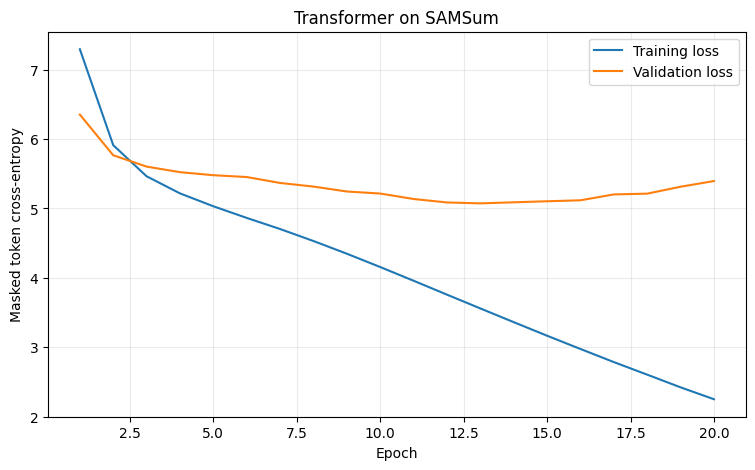

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), history["train_loss"], label="Training loss")
plt.plot(range(1, EPOCHS + 1), history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Masked token cross-entropy")
plt.title("Transformer on SAMSum")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [14]:
def next_word(model, encoder_input, output):
    enc_padding_mask = create_padding_mask(encoder_input)
    look_ahead_mask = create_look_ahead_mask(tf.shape(output)[1])
    dec_padding_mask = create_padding_mask(encoder_input)

    predictions = model(
        encoder_input,
        output,
        training=False,
        enc_padding_mask=enc_padding_mask,
        look_ahead_mask=look_ahead_mask,
        dec_padding_mask=dec_padding_mask,
    )
    next_logits = tf.cast(predictions[:, -1:, :], tf.float32)
    vocab_mask = tf.one_hot([PAD_ID, SOS_ID], depth=vocab_size, on_value=True, off_value=False)
    forbidden = tf.reduce_any(vocab_mask, axis=0)
    next_logits = tf.where(forbidden[tf.newaxis, tf.newaxis, :], -1e9, next_logits)
    return tf.argmax(next_logits, axis=-1, output_type=tf.int32)


def summarize(model, input_document, max_new_tokens=decoder_maxlen - 1):
    prepared = prepare_text(input_document)
    sequence = tokenizer.texts_to_sequences([prepared])
    encoder_ids = tf.keras.preprocessing.sequence.pad_sequences(
        sequence, maxlen=encoder_maxlen, padding="post", truncating="post"
    )
    encoder_input = tf.convert_to_tensor(encoder_ids, dtype=tf.int32)
    output = tf.constant([[SOS_ID]], dtype=tf.int32)

    for _ in range(max_new_tokens):
        predicted_id = next_word(model, encoder_input, output)
        token_id = int(predicted_id[0, 0].numpy())
        if token_id == EOS_ID:
            break
        output = tf.concat([output, predicted_id], axis=-1)

    generated_ids = output.numpy()[0].tolist()[1:]
    generated_text = tokenizer.sequences_to_texts([generated_ids])[0]
    return generated_text.strip()

print("Inference function ready.")

Inference function ready.


In [15]:
for index in range(min(5, len(val_records))):
    record = val_records[index]
    prediction = summarize(transformer, record["dialogue"])
    print("=" * 85)
    print(f"VALIDATION EXAMPLE {index + 1}")
    print("DIALOGUE:", record["dialogue"][:1200])
    print("REFERENCE:", record["summary"])
    print("GENERATED:", prediction)

/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 8, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


VALIDATION EXAMPLE 1
DIALOGUE: A: Hi Tom, are you busy tomorrow’s afternoon? B: I’m pretty sure I am. What’s up? A: Can you go with me to the animal shelter?. B: What do you want to do? A: I want to get a puppy for my son. B: That will make him so happy. A: Yeah, we’ve discussed it many times. I think he’s ready now. B: That’s good. Raising a dog is a tough issue. Like having a baby ;-) A: I'll get him one of those little dogs. B: One that won't grow up too big;-) A: And eat too much;-)) B: Do you know which one he would like? A: Oh, yes, I took him there last Monday. He showed me one that he really liked. B: I bet you had to drag him away. A: He wanted to take it home right away ;-). B: I wonder what he'll name it. A: He said he’d name it after his dead hamster – Lemmy - he's a great Motorhead fan :-)))
REFERENCE: A will go to the animal shelter tomorrow to get a puppy for her son. They already visited the shelter last Monday and the son chose the puppy.
GENERATED: tom is busy with hi

In [16]:
dinner_dialogue = """hey babe, what do you want for dinner tonight? emma: gah, don't even worry about it tonight will: what do you mean? everything ok? emma: not really, but it's ok, don't worry about cooking though, i'm not hungry will: well what time will you be home? emma: soon, hopefully will: you sure? maybe you want me to pick you up? emma: no no it's alright. i'll be home soon, i'll tell you when i get home. will: alright, love you. emma: love you too."""

print("REFERENCE INTERPRETATION: Emma is upset and is not hungry. She expects to be home soon and will let Will know when she arrives. Will offers to pick her up, but she declines.")
print("\nMODEL SUMMARY:")
print(summarize(transformer, dinner_dialogue))

REFERENCE INTERPRETATION: Emma is upset and is not hungry. She expects to be home soon and will let Will know when she arrives. Will offers to pick her up, but she declines.

MODEL SUMMARY:
emma and emma are going to have dinner tonight emma will pick emma up from school


In [17]:
for index in range(min(5, len(test_records))):
    record = test_records[index]
    prediction = summarize(transformer, record["dialogue"])
    print("=" * 85)
    print(f"TEST EXAMPLE {index + 1}")
    print("DIALOGUE:", record["dialogue"][:1000])
    print("REFERENCE:", record["summary"])
    print("GENERATED:", prediction)

TEST EXAMPLE 1
DIALOGUE: Hannah: Hey, do you have Betty's number? Amanda: Lemme check Hannah: Amanda: Sorry, can't find it. Amanda: Ask Larry Amanda: He called her last time we were at the park together Hannah: I don't know him well Hannah: Amanda: Don't be shy, he's very nice Hannah: If you say so.. Hannah: I'd rather you texted him Amanda: Just text him 🙂 Hannah: Urgh.. Alright Hannah: Bye Amanda: Bye bye
REFERENCE: Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.
GENERATED: hannah is going to see hannah at the pub hannah will let hannah know if she can get her phone
TEST EXAMPLE 2
DIALOGUE: Eric: MACHINE! Rob: That's so gr8! Eric: I know! And shows how Americans see Russian ;) Rob: And it's really funny! Eric: I know! I especially like the train part! Rob: Hahaha! No one talks to the machine like that! Eric: Is this his only stand-up? Rob: Idk. I'll check. Eric: Sure. Rob: Turns out no! There are some of his stand-ups on youtube. Eric: Gr8! I'll wa